# Detecting Cheating in Online Chess: A Hybrid Approach Using CNN-LSTM and XGBoost for Identifying Computer Assistance

### Jave Atanacio Bacsain BSCS-2A (As a requirement for the course of CSAC 212 - Introduction to Artificial Intelligence)
# FINAL PROJECT

# 
### Introduction

This project focuses on detecting cheating in online chess platforms by utilizing machine learning techniques to analyze chess game data. The primary dataset used in this project is Games.csv, sourced from Kaggle, which contains information about various chess games played online. The dataset provides valuable details such as player moves, game results, and chess elo, but it requires further processing to make it suitable for training a model capable of detecting cheating patterns.

To prepare the dataset, I first modified code from a related paper on chess Elo rating prediction using CNN-LSTM, with permission from the original authors. This code was adapted to process the chess games in Games.csv and convert them into board states for further analysis. The conversion process was handled by a Python script named gameprocessor.py, which transforms the game data into individual board states that represent each move in the game. These board states are saved as individual pickle (.pkl) files in a directory called "games. (NOTE THAT THE .pkl FILES ARE NOT INCLUDED IN THE SUBMISSION DUE TO ITS LARGE SIZE)"

The next step involved predicting the Elo ratings of players, which is a critical feature for identifying suspicious behavior. I used a pre-trained CNN-LSTM model from the referenced paper to predict the Elo ratings. The model, saved as model_55.pth, was used in the rating_prediction.py script to generate predictions for each game in the dataset. These predictions, stored in the predictions.csv file, serve as a crucial feature for further analysis.

Finally, the predicted Elo ratings, along with the original data from Games.csv, were used as features to train an XGBoost classifier. The goal of the model is to detect potential cheating by identifying patterns in the gameplay that may indicate the use of chess engines. The combination of board state information and Elo rating predictions enables the model to analyze gameplay more effectively, improving the accuracy of cheating detection in online chess games.





Omori, M., & Tadepalli, P. (2024). Chess Rating Estimation from Moves and Clock Times Using a
CNN-LSTM. ArXiv, abs/2409.11506
(https://github.com/AstroBoy1/RatingNet)

Spotting Cheaters: Chess cheating dataset. (2024, April 1). Kaggle. 
(https://www.kaggle.com/datasets/brieucdandoy/chess-cheating-dataset/data)

# Dependencies and Setup

To ensure the smooth operation of the project, I began by setting up the necessary libraries and modules. The primary tools leveraged in this project include pandas for data manipulation, seaborn and matplotlib for data visualization, and XGBoost for building the classification model. Additionally, I integrated AutoLogger to track experimental progress and used profiling utilities to enhance my understanding of the dataset. These tools collectively facilitate efficient data analysis and model training.

In [73]:
#!pip install ydata-profiling
#!pip install AutoLogging-ML
#!pip install xgboost
#!pip install catboost

import pandas as pd
import numpy as np
import csv
import seaborn as sns

from AutoLogging_ML import AutoLogger
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report , confusion_matrix
from sklearn.metrics import accuracy_score
from ydata_profiling import ProfileReport
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Combining CSV Files

The data was sourced from two separate CSV files: predictions.csv and Games.csv, which contained complementary but distinct information. The task involved aligning these files row-wise, ensuring that the data from both sources could be combined into a unified dataset. I implemented a script using Python's csv module to read, match, and merge the rows of the files, saving the combined result into a new CSV file for further processing.

In [74]:
predictions_file = 'predictions.csv'
games_file = 'Games.csv'
output_file = 'combined_data.csv'

# Read the content of a CSV file
def read_csv(file_path):
    with open(file_path, 'r') as file:
        reader = csv.reader(file)
        data = list(reader)
    return data

# Write combined content to a new file
def write_csv(file_path, data):
    with open(file_path, 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerows(data)

# Load both files
predictions_data = read_csv(predictions_file)
games_data = read_csv(games_file)

# Ensure both files have the same number of rows for alignment
if len(predictions_data) != len(games_data):
    raise ValueError("The two files do not have the same number of rows for combining columns.")

# Combine the data as new columns
header = predictions_data[0] + games_data[0]  # Combine headers
combined_data = [header] + [pred_row + game_row for pred_row, game_row in zip(predictions_data[1:], games_data[1:])]

# Save the combined data
write_csv(output_file, combined_data)

print(f"Combined data saved to {output_file}")


Combined data saved to combined_data.csv


# Dataset Preview

Upon combining the datasets, the next step was to load the data into a pandas DataFrame for a preliminary inspection. At this stage, it was important to review how the data was structured after the merging process. The dataset was previewed to identify any apparent issues or anomalies before proceeding with further transformations and analyses.

In [75]:
df = pd.read_csv('combined_data.csv')
df

,Row,White Prediction,Black Prediction,Liste cheat white,Liste cheat black,Game,Elo White,Elo Black,Score
0,0,2013.659424,2015.224121,00000000001111101010111010100110000001001111,0000000000111001000000001100100000000111000,1. d4 e6 2. c4 d5 3. Nc3 Be7 4. Nf3 Nf6 5. Bf4...,1001,-1,1/2-1/2
1,1,1996.151733,1997.726318,0000000000000010111101100000100111000111101111001,0000000000110111110111111111111111111011111111111,1. d4 c5 2. c4 cxd4 3. Qxd4 Nc6 4. Qd1 e6 5. N...,1001,-1,1/2-1/2
2,2,1511.751831,1513.163940,0000000000111001110111100111111110101011110111...,0000000000111111100001111111111111111111010101...,1. e4 e5 2. d4 exd4 3. Qxd4 Nc6 4. Qd3 b6 5. B...,1001,-1,1/2-1/2
3,3,1521.371582,1522.777832,000000000011111101111111110110101111111,00000000000001101001000011100111100110,1. e4 e5 2. Nf3 Nf6 3. Nc3 Bc5 4. Bc4 d6 5. O-...,1002,-1,1/2-1/2
4,4,1542.092529,1543.494873,0000000000001000111010111101001010011010011011...,0000000000000000010000001110011010100010001100...,1. d4 d5 2. c4 Nf6 3. Nc3 e6 4. Bg5 Be7 5. e3 ...,1002,-1,1/2-1/2
...,...,...,...,...,...,...,...,...,...
48927,48927,1550.246948,1551.718384,00000000000000000000000000000,00000000001001000000110010111,1. e4 e5 2. Qh5 Qe7 3. Bc4 Nf6 4. Qf3 d6 5. h3...,1841,1806,0-1
48928,48928,1337.956055,1339.301147,0000000000000000000000000000000000000000,0000000000110011011110011111101110101001,1. c4 d5 2. c5 c6 3. b4 Bf5 4. d3 e6 5. Bf4 Nd...,1562,1561,0-1
48929,48929,1765.669678,1767.174927,0000000000000000000000000000000000000000000000...,0000000000100110100100000100001000100100100110...,1. e4 e5 2. Bc4 Nf6 3. Nf3 d6 4. Ng5 Be6 5. Bx...,1476,1420,1-0
48930,48930,1700.737915,1702.206543,0000000000000000000000000000000,000000000010000001000000010100,1. d4 Nf6 2. c4 g6 3. Nc3 e6 4. Nf3 Bg7 5. e4 ...,1745,1536,1-0


# Feature Engineering

This phase marked a significant step in preparing the dataset for model training. I split the Score column into two distinct fields: score_1 and score_2, which represent the individual results of each player. From these scores, I derived a new result column to categorize the outcomes of each game into three possible categories: 0 for a white win, 1 for a black win, and 2 for a draw.

In [76]:
df[['score_1', 'score_2']] = df['Score'].str.split('-', expand=True)

df['result'] = df.apply(lambda row: 0 if row['score_1'] == '1' else (1 if row['score_2'] == '1' else 2), axis=1)

df = df.drop(columns=['score_1', 'score_2'])
df

,Row,White Prediction,Black Prediction,Liste cheat white,Liste cheat black,Game,Elo White,Elo Black,Score,result
0,0,2013.659424,2015.224121,00000000001111101010111010100110000001001111,0000000000111001000000001100100000000111000,1. d4 e6 2. c4 d5 3. Nc3 Be7 4. Nf3 Nf6 5. Bf4...,1001,-1,1/2-1/2,2
1,1,1996.151733,1997.726318,0000000000000010111101100000100111000111101111001,0000000000110111110111111111111111111011111111111,1. d4 c5 2. c4 cxd4 3. Qxd4 Nc6 4. Qd1 e6 5. N...,1001,-1,1/2-1/2,2
2,2,1511.751831,1513.163940,0000000000111001110111100111111110101011110111...,0000000000111111100001111111111111111111010101...,1. e4 e5 2. d4 exd4 3. Qxd4 Nc6 4. Qd3 b6 5. B...,1001,-1,1/2-1/2,2
3,3,1521.371582,1522.777832,000000000011111101111111110110101111111,00000000000001101001000011100111100110,1. e4 e5 2. Nf3 Nf6 3. Nc3 Bc5 4. Bc4 d6 5. O-...,1002,-1,1/2-1/2,2
4,4,1542.092529,1543.494873,0000000000001000111010111101001010011010011011...,0000000000000000010000001110011010100010001100...,1. d4 d5 2. c4 Nf6 3. Nc3 e6 4. Bg5 Be7 5. e3 ...,1002,-1,1/2-1/2,2
...,...,...,...,...,...,...,...,...,...,...
48927,48927,1550.246948,1551.718384,00000000000000000000000000000,00000000001001000000110010111,1. e4 e5 2. Qh5 Qe7 3. Bc4 Nf6 4. Qf3 d6 5. h3...,1841,1806,0-1,1
48928,48928,1337.956055,1339.301147,0000000000000000000000000000000000000000,0000000000110011011110011111101110101001,1. c4 d5 2. c5 c6 3. b4 Bf5 4. d3 e6 5. Bf4 Nd...,1562,1561,0-1,1
48929,48929,1765.669678,1767.174927,0000000000000000000000000000000000000000000000...,0000000000100110100100000100001000100100100110...,1. e4 e5 2. Bc4 Nf6 3. Nf3 d6 4. Ng5 Be6 5. Bx...,1476,1420,1-0,0
48930,48930,1700.737915,1702.206543,0000000000000000000000000000000,000000000010000001000000010100,1. d4 Nf6 2. c4 g6 3. Nc3 e6 4. Nf3 Bg7 5. e4 ...,1745,1536,1-0,0


# Cheating Metrics

To analyze the potential for cheating within the dataset, I focused on the Liste cheat white and Liste cheat black columns, which indicate flagged suspicious behavior during the games. By counting the number of instances where players were flagged as cheating, I generated new features that reflect the frequency of suspicious activity. This helped in understanding potential cheating tendencies within the dataset.

In [77]:
def count_ones(series):
    return series.count('1')

df['Liste cheat white'] = df['Liste cheat white'].apply(count_ones)

In [78]:
df['Liste cheat black'] = df['Liste cheat black'].apply(count_ones)
df

,Row,White Prediction,Black Prediction,Liste cheat white,Liste cheat black,Game,Elo White,Elo Black,Score,result
0,0,2013.659424,2015.224121,19,10,1. d4 e6 2. c4 d5 3. Nc3 Be7 4. Nf3 Nf6 5. Bf4...,1001,-1,1/2-1/2,2
1,1,1996.151733,1997.726318,20,36,1. d4 c5 2. c4 cxd4 3. Qxd4 Nc6 4. Qd1 e6 5. N...,1001,-1,1/2-1/2,2
2,2,1511.751831,1513.163940,43,41,1. e4 e5 2. d4 exd4 3. Qxd4 Nc6 4. Qd3 b6 5. B...,1001,-1,1/2-1/2,2
3,3,1521.371582,1522.777832,25,13,1. e4 e5 2. Nf3 Nf6 3. Nc3 Bc5 4. Bc4 d6 5. O-...,1002,-1,1/2-1/2,2
4,4,1542.092529,1543.494873,34,15,1. d4 d5 2. c4 Nf6 3. Nc3 e6 4. Bg5 Be7 5. e3 ...,1002,-1,1/2-1/2,2
...,...,...,...,...,...,...,...,...,...,...
48927,48927,1550.246948,1551.718384,0,8,1. e4 e5 2. Qh5 Qe7 3. Bc4 Nf6 4. Qf3 d6 5. h3...,1841,1806,0-1,1
48928,48928,1337.956055,1339.301147,0,20,1. c4 d5 2. c5 c6 3. b4 Bf5 4. d3 e6 5. Bf4 Nd...,1562,1561,0-1,1
48929,48929,1765.669678,1767.174927,0,12,1. e4 e5 2. Bc4 Nf6 3. Nf3 d6 4. Ng5 Be6 5. Bx...,1476,1420,1-0,0
48930,48930,1700.737915,1702.206543,0,4,1. d4 Nf6 2. c4 g6 3. Nc3 e6 4. Nf3 Bg7 5. e4 ...,1745,1536,1-0,0


# Dataset Cleaning

At this stage, I cleaned the dataset by removing columns that were deemed unnecessary for the modeling process, such as Score, Game, and Row. This step streamlined the dataset, ensuring that only relevant features were included, making the dataset more manageable and focused for model training.

In [79]:
df.drop('Score',inplace=True,axis=1)

In [80]:
df.drop('Game',inplace=True,axis=1)

In [81]:
df.drop('Row',inplace=True,axis=1)

In [82]:
y = df['result']
X = df.drop('result',axis=1)

In [83]:
df_cleaned = df

# Dataset Overview

After cleaning the dataset, I conducted several checks to ensure its integrity. These checks included verifying data types, summarizing statistical information, and identifying any missing values. This crucial step helped me confirm that the dataset was in proper shape for modeling and that there would be no unexpected issues during training.

In [84]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48932 entries, 0 to 48931
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   White Prediction   48932 non-null  float64
 1   Black Prediction   48932 non-null  float64
 2   Liste cheat white  48932 non-null  int64  
 3   Liste cheat black  48932 non-null  int64  
 4   Elo White          48932 non-null  int64  
 5   Elo Black          48932 non-null  int64  
 6   result             48932 non-null  int64  
dtypes: float64(2), int64(5)
memory usage: 2.6 MB


In [85]:
df_cleaned.describe()

,White Prediction,Black Prediction,Liste cheat white,Liste cheat black,Elo White,Elo Black,result
count,48932.000000,48932.000000,48932.000000,48932.000000,48932.000000,48932.000000,48932.000000
mean,1750.347868,1751.843543,7.264285,8.645855,1639.237002,1727.008379,0.771928
std,220.300907,220.373250,12.066849,12.587339,427.412696,243.106285,0.718507
min,901.131287,902.401489,0.000000,0.000000,-1.000000,-1.000000,0.000000
25%,1610.085938,1611.517212,0.000000,0.000000,1543.000000,1604.000000,0.000000
50%,1774.504028,1776.023865,0.000000,1.000000,1749.000000,1774.000000,1.000000
75%,1907.449860,1909.010376,12.000000,14.000000,1886.000000,1897.000000,1.000000
max,2348.081055,2349.742676,165.000000,166.000000,2616.000000,2615.000000,2.000000


In [86]:
df_cleaned.isna().sum()

White Prediction     0
Black Prediction     0
Liste cheat white    0
Liste cheat black    0
Elo White            0
Elo Black            0
result               0
dtype: int64

# Exploratory Data Analysis (EDA)

To further understand the characteristics of the dataset, I utilized ydata_profiling to generate a detailed report of the dataset's features. This tool provided an in-depth analysis of statistical distributions, correlations, and potential outliers. The insights gained from this analysis were instrumental in guiding the feature engineering process and understanding the underlying patterns in the data.

In [87]:
profile = ProfileReport(df,title = 'ChessCheating')
profile.to_notebook_iframe()
profile.to_file("books_data.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

# Preparing Data for Modeling

With the dataset now ready, I split it into features (X) and the target variable (y). The result column became the target, while the remaining columns served as predictors. To ensure a robust evaluation of the model, I divided the data into training and testing sets, which enabled me to assess its performance on unseen data.

In [88]:
print(X.shape)
print(y.shape)

(48932, 6)
(48932,)


In [89]:
x_train,x_test,y_train,y_test= train_test_split(X,y,random_state = 42,test_size=0.2)

# Building the XGBoost Model

In this code, I configure the hyperparameters for the XGBClassifier and then train the model using the training data. After fitting the model, I use it to make predictions on the test data and store the results. The hyperparameters were selected through a trial-and-error process with the goal of optimizing the model's performance.

In [119]:
xgboost_model = XGBClassifier()

params = {
    'max_depth': 7,                
    'learning_rate': 0.05,          
    'colsample_bytree': 1.0,       
    'subsample': 0.7,             
    'reg_alpha': 1,               
    'reg_lambda': 1,               
    'n_estimators': 1,         
    'random_state': 42
}

xgboost_model = XGBClassifier(**params)

xgboost_model.fit(x_train, y_train)
y_pred = xgboost_model.predict(x_test)

# Training and Evaluation

The training phase was straightforward, and the model exhibited promising results. I evaluated the model's performance using accuracy as the primary metric, complemented by a confusion matrix and a classification report.

In [120]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Validation Accuracy: {accuracy:.4f}")

Validation Accuracy: 0.6824


In [92]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3258  620   27]
 [ 956 3213   36]
 [ 912  526  239]]


In [93]:
cr = classification_report(y_test, y_pred)
print("Classification Report:")
print(cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.83      0.72      3905
           1       0.74      0.76      0.75      4205
           2       0.79      0.14      0.24      1677

    accuracy                           0.69      9787
   macro avg       0.72      0.58      0.57      9787
weighted avg       0.71      0.69      0.65      9787



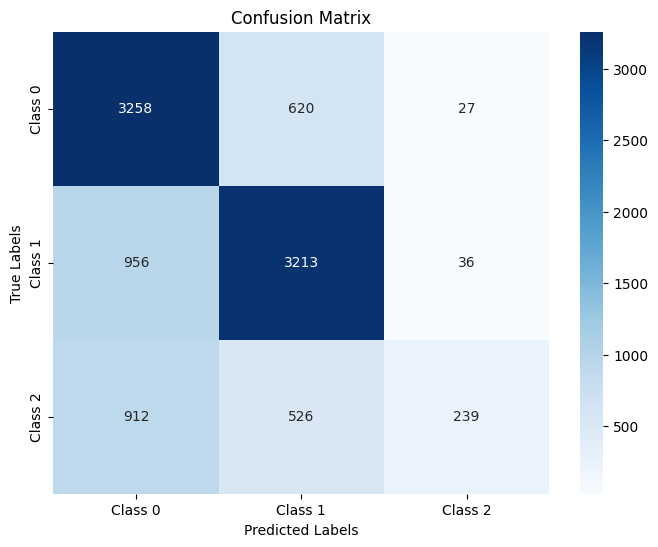

In [94]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1', 'Class 2'], yticklabels=['Class 0', 'Class 1', 'Class 2'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

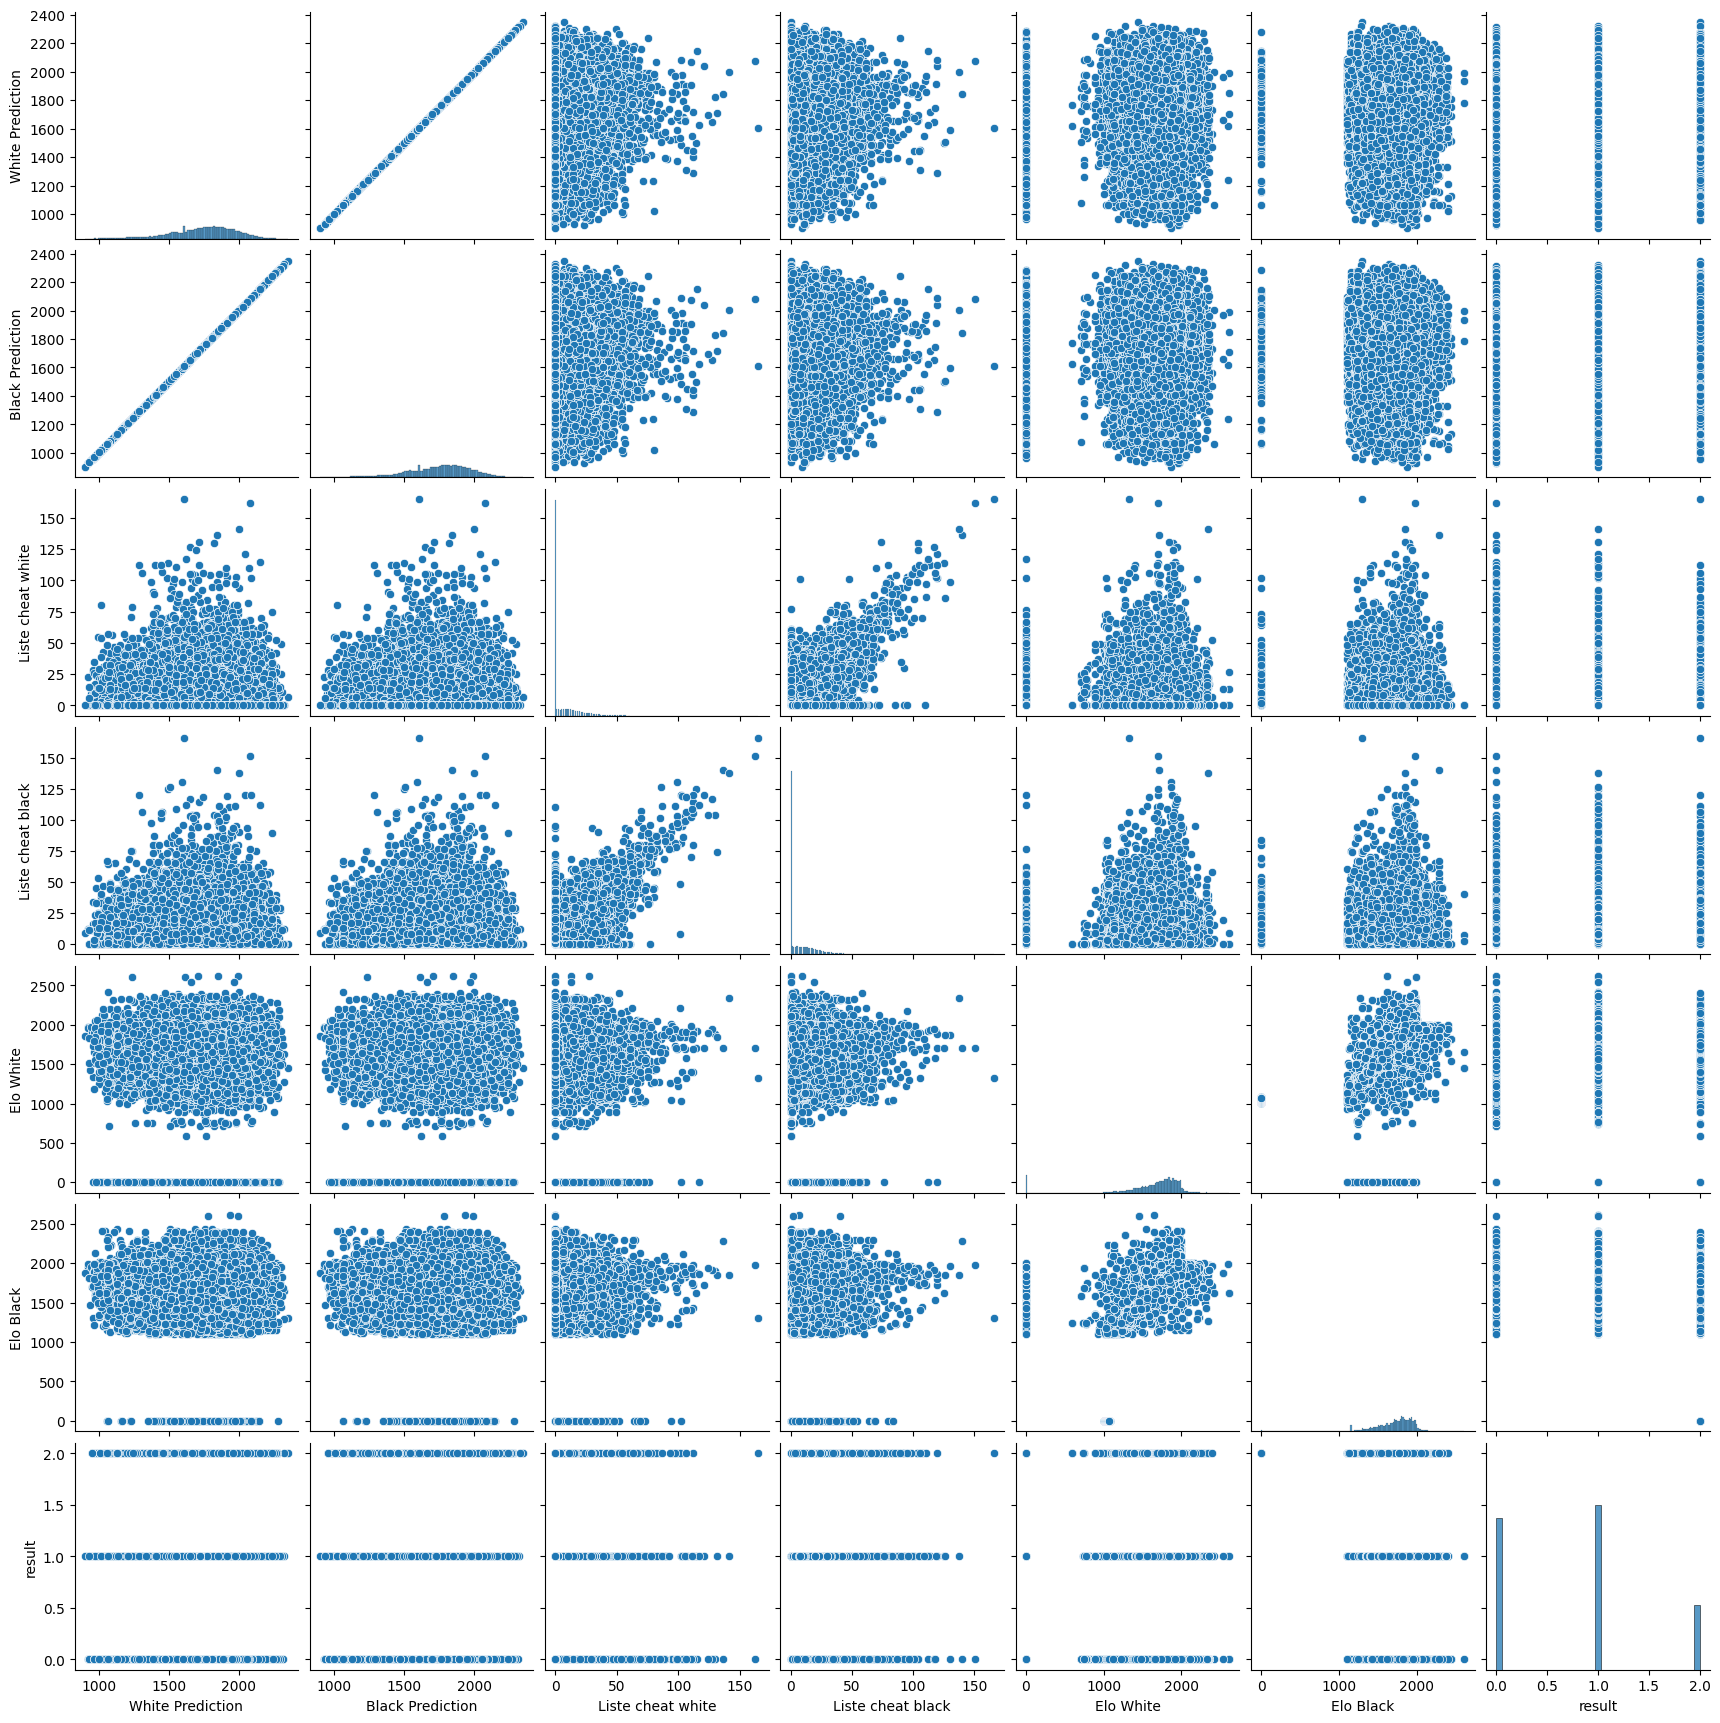

In [95]:
sns.pairplot(df_cleaned)

# Display the pairplot
plt.show()

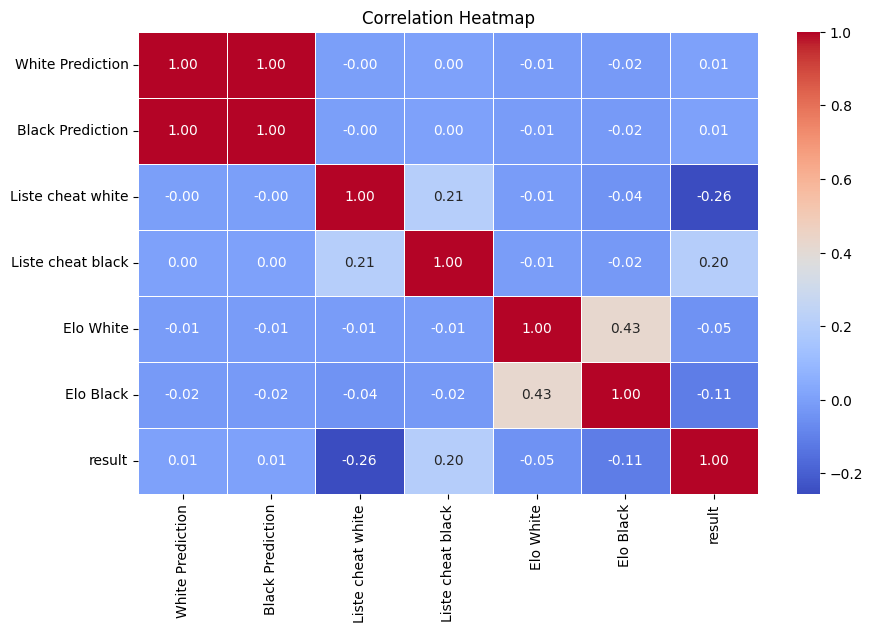

In [101]:
plt.figure(figsize=(10, 6))
correlation_matrix = df_cleaned.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()
